# Q1

The data in the table below shows the line-of-sight component of the velocity of a _star_ as observed from Earth as a function of time. (The planet is too faint to detect photometrically, let alone take a spectrum of!)

The data have first been corrected for the rotation of the Earth and its orbit around the Sun, i.e. to the frame of the barycentre of our Solar system. Then they have been corrected (by MH) to the barycentre of the remote system by removing a mean offset, so you may assume that, for these corrected data, 0 m/s is the average radial velocity of the star.

This is real data, but the orbit of this system is actually close to circular, so we will neglect the parameters associated with its ellipticity and assume a _circular_ orbit. The data can then be described by three numbers: a <mark>frequency or period</mark>, a <mark>phase</mark> and an <mark>amplitude</mark>.

Day 0 is arbitrary. The time is in <mark>days</mark> and the velocity is in units of <mark> _metres_/_second_</mark>.

In [1]:
import numpy as np

import matplotlib
import matplotlib.pyplot as plt

# Adjust default font size so that labels are readable in plots
font = {'size': 18}
matplotlib.rc('font', **font)

In [2]:
import astropy.table

tab = astropy.table.Table.read('Planet.csv', format='ascii.csv')
tab

Day,Radial_Velocity,Radial_Velocity_Uncertainty
float64,float64,float64
2.67293,-50.85763971946289,1.3451385
2.80777,-55.37167780946289,1.4675213
2.96133,-59.88485757946289,1.8407817
3.62656,-31.755737709462892,1.1571392
3.73272,-23.92064897946289,0.9810482
3.90064,-10.60241834946289,1.2261995
4.60587,39.713584490537116,0.9482159
4.78459,46.14331777053712,1.077486
4.90837,49.837340900537114,1.3151617


In [3]:
# Convert columns to more useful format
time = tab['Day'].data
v = tab['Radial_Velocity'].data
err = tab['Radial_Velocity_Uncertainty'].data

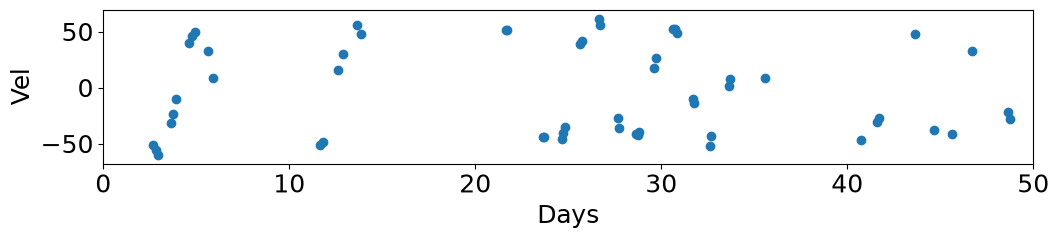

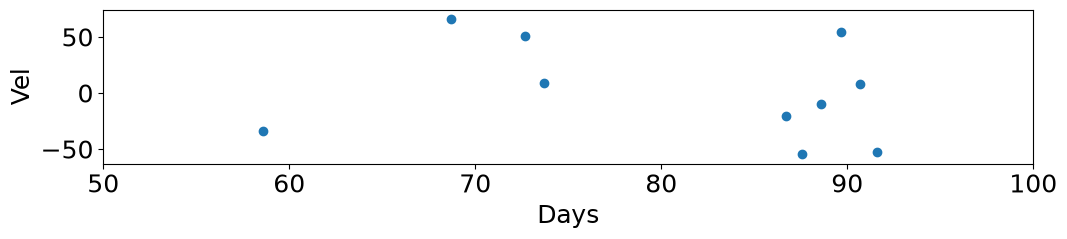

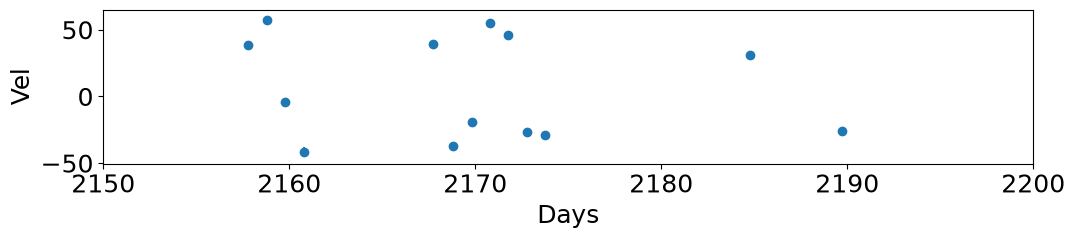

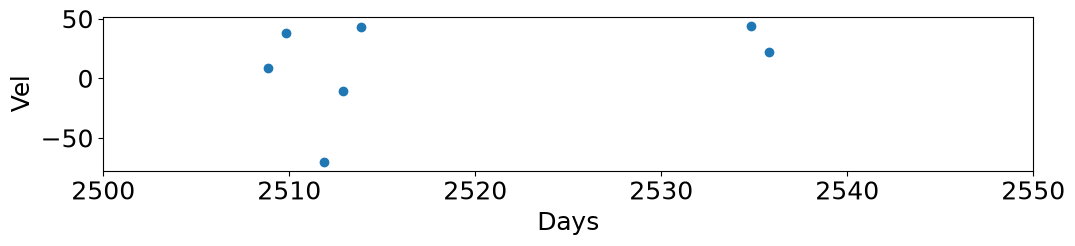

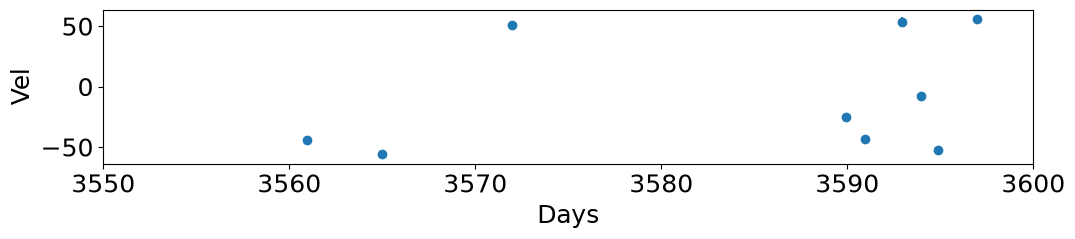

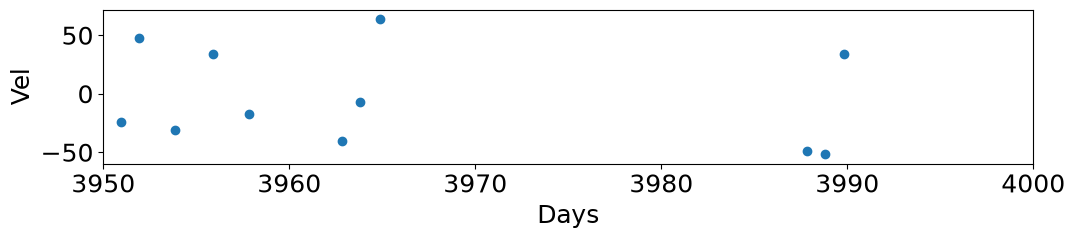

In [4]:
step = 50
for i,start in enumerate(np.arange(0, 6000, step)):
    end = start + step
    sel = np.logical_and(time > start, time < end)
    
    # Only plot the figure if there are a reasonable number of points in the range
    if len(time[sel]) > 6:
        fig = plt.figure(num=i, figsize=[12.,2.], dpi=100)
        plt.errorbar(time[sel],v[sel],err[sel],marker='o',ls='')
        plt.xlim((start,start+50))
        plt.xlabel("Days")
        plt.ylabel("Vel")

It looks like the first 50 days are amongst the best. You can use those for practice.

### Fitting the time series

Time series like these are very tricky; due to aliasing, there are many local minima.

So you will need some tricks to start your minimizer from a _good initial guess_. 

   * One of these "tricks" is to use your eyes: what is the range covered by the data? Can you guess the period? 

   * A second trick is to use a periodogram (one tuned for unevenly sampled data: FFT will not work well here - see Chapter 10 of SDMMMLA) to get an improved guess for the frequency or period.
    
Once you have made some guesses, for each guess plot your fit in two different ways 

   1. Over all the points (you can use the plotting scripts above).

   2. "Fold" all of the data. In other words, suppose you have fitted a period of 5 days. Then plot all data point with the x-axis having a range 0-5, and where a measurement taken at 8 days is plotted at 8 - (5 * 1) = 3, one at 14 days is plotted at 14- (2 * 5) = 4 and so on.

Now try using ``lmfit`` with the default least squares. Can you get it to converge to the correct answer? 

(If you have trouble, try working with only the first 50 days worth of data first, as a warmup).

<mark>_Show your final work as well as all your exploratory work and tests_. </mark>

Use as many cells as you need, mixing Markdown/LaTeX with code, as necessary.

---

## Start of my solution

Starting with only first 50 days of data

In [5]:
import matplotlib.ticker as ticker

# Select only first 50 days of data to start
isWithinFirst50days = np.logical_and(time >= 0 , time <= 50)
t50 = time[isWithinFirst50days]
v50 = v[isWithinFirst50days]
err50 = err[isWithinFirst50days]

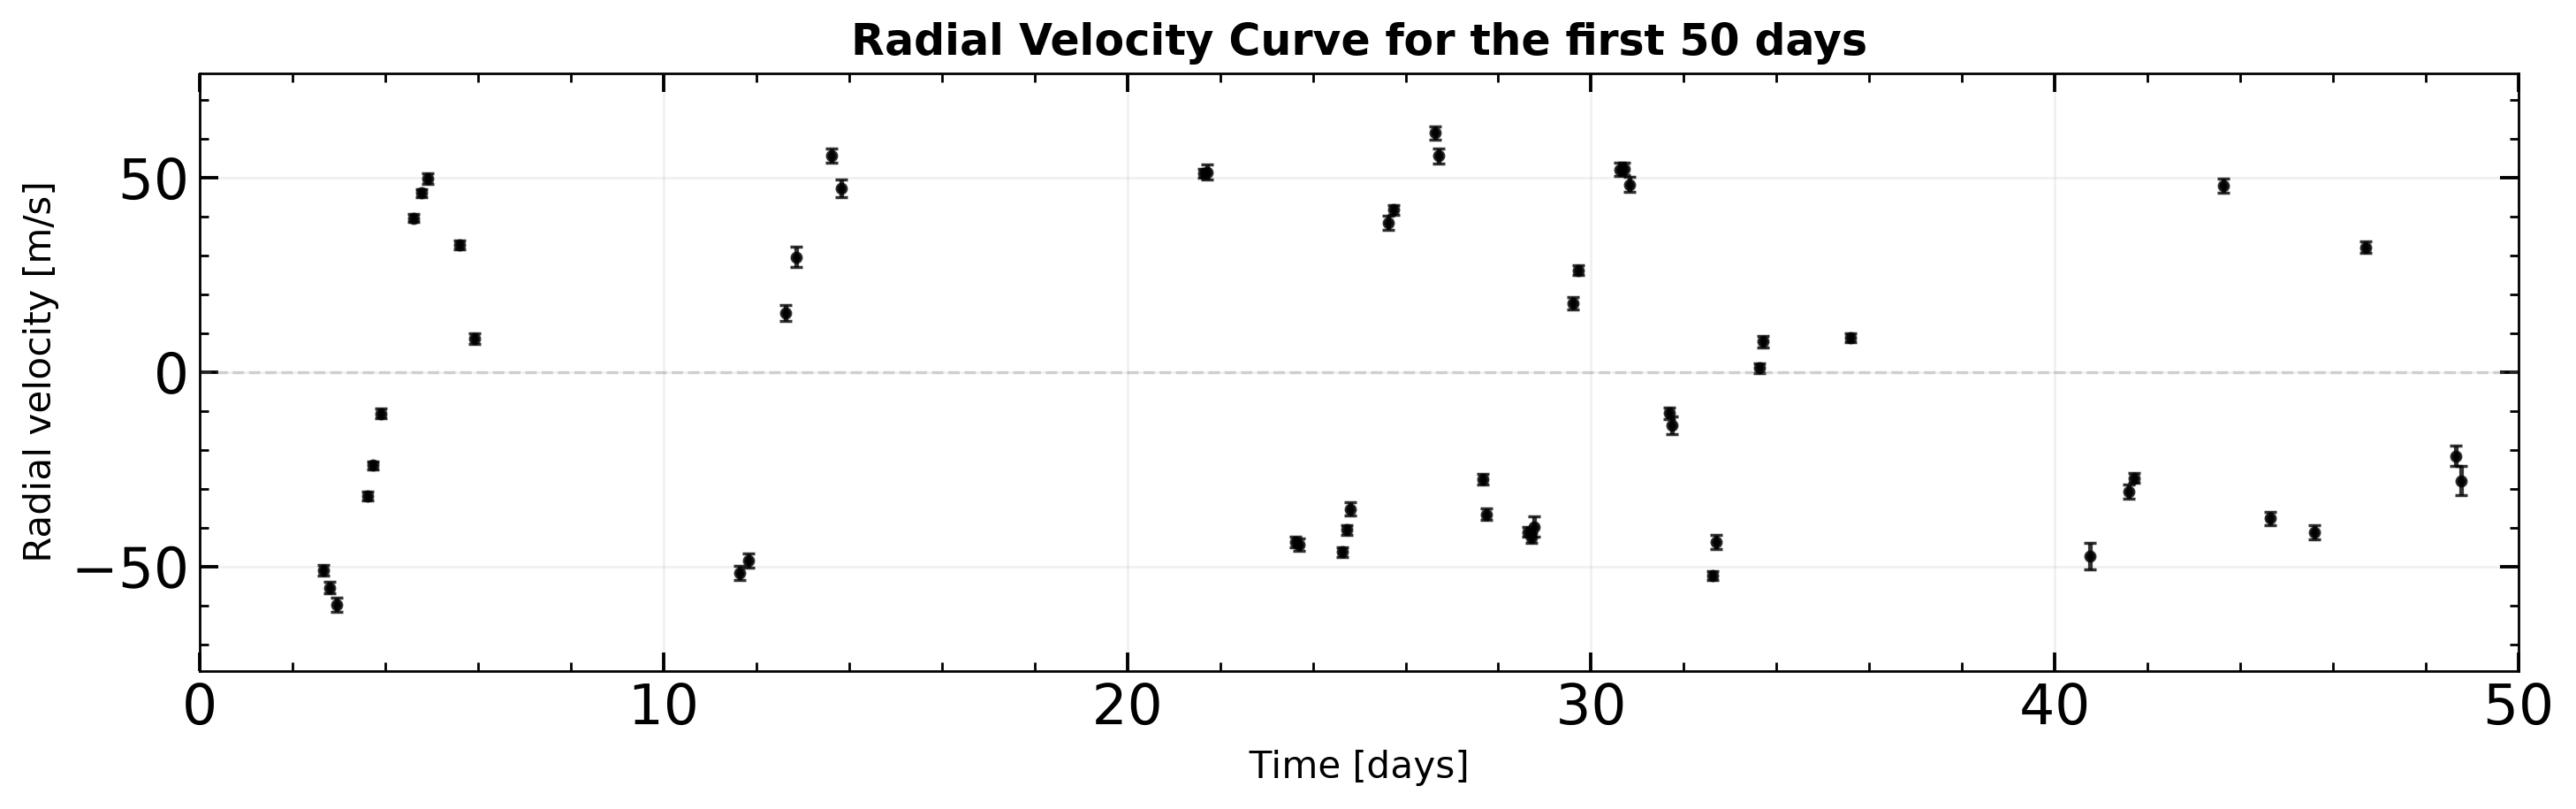

In [6]:
fig, ax = plt.subplots(figsize=(12, 4), dpi=250)

ax.scatter(t50, v50, color="black", s = 1.0,zorder = 2)
# Error bars 
ax.errorbar(
    t50,
    v50,
    yerr=err50,
    fmt="o",
    ms=3.0,
    color='black',
    alpha=.8,
    capsize=2,
    #label="",
    #lw = 1
)
ax.axhline(0, color='gray', lw=1, ls="--", alpha=0.3)

ax.set_xlabel("Time [days]", fontsize=12)
ax.set_ylabel("Radial velocity [m/s]", fontsize=12)
ax.set_title("Radial Velocity Curve for the first 50 days", fontsize=14, fontweight="bold")

ax.set_xlim(0, 50)

# make y-limits symmetric around zero
rv_absmax = max(abs(v50.min()), abs(v50.max()))
ax.set_ylim(-1.25 * rv_absmax, 1.25 * rv_absmax)

# ticks on all four sides
ax.tick_params(axis="both", which="major", direction="in", length=6, width=1.1, top=True, right=True)
ax.tick_params(axis="both", which="minor", direction="in", length=3, width=0.8, top=True, right=True)
ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.grid(True, which="major", alpha=0.18, lw=0.8)
# ax.legend(frameon=False, fontsize=9, loc="best")
fig.tight_layout()
plt.show()

For a circular orbit, the radial velocity will depend only on the period, phase, and semi-amplitude. This comes from the general equation
\begin{equation*}
    v_r(t) = K \bigg[ \cos{\big(\omega + \nu(t)\big)} + e\cos{\omega} \bigg] + v_{\rm sys}
\end{equation*}
reducing to 
\begin{equation*}
    \boxed{ v_r(t) = K \cos{\bigg(\frac{2\pi t}{P} + \phi \bigg)} }
\end{equation*}
when $e = 0, v_{\rm sys} = 0$

---

# Q2

## MCMC

The goal is to _write your own Metropolis-Hastings MCMC code_, to find the best fit and its uncertainties in the parameters.

* You can follow the ideas [here](http://twiecki.github.io/) or [here](http://dfm.io/emcee/current/user/line/#the-generative-probabilistic-model) - note the use of priors to exclude regions of parameter space that you do not wish to fit.

* You should test your MCMC code on an easy case with known solution (e.g. a straight line fit with known parameters and simulated data that you generate yourself).

## Application to the above time series from Q1

You will need a good starting guess not only for the values of the parameters but also for the _range_, so that you can make a sensible proposal distribution.

Try a range of proposal distributions and a range of starting guesses (including some local-not-global minima).

Plot the chains and results and comment on the behaviour of the chains.

Once you have a final fit to _all_ of the data from your MCMC code, 

1. Make a _corner plot_ of the fitted parameters (you can use the package)
2. Plot the best fit velocity curve on top of the data (as described above), and show the range allowed by the fitted parameter uncertainties as a light shaded band.

_Show your final work as well as all your exploratory work and tests_. 

Use as many cells as you need, mixing Markdown/LaTeX with code, as necessary.

---

## Start of my solution

---